# Phase retrieval with the transport-of-intensity equation (TIE)

Cameras measure only intensities. A transparent object (e.g. a cell or a glass
structure), however, changes almost only the phase and is practically invisible
in focus. Defocus a little, and it becomes visible: phase gradients redirect
light, curved phase gathers or spreads it like a lens. The
**transport-of-intensity equation** describes this quantitatively:

$$k\,\frac{\partial I}{\partial z} = -\nabla_\perp\cdot\big(I\,\nabla_\perp\varphi\big).$$

Two slightly defocused images give $\partial I/\partial z$, and the equation (a
Poisson equation) can be solved for the phase $\varphi$. `pyoptics.TIE` provides
`tie()` (forward direction), `solve_tie()` (solution via FFT) and
`enhanced_tie_solve()` (iterative refinement).

**Convention:** $\exp(i(kz - \omega t))$, the field is $\sqrt{I}\,e^{i\varphi}$. A
converging wave (phase falling off outwards, as behind a converging lens) has
$\partial I/\partial z > 0$ on the axis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import TIE
from pyoptics.propagators import rayleigh_sommerfeld_I_TF
from pyoptics.utils import grid2d, get_z_derivative

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 0.5
k = 2*np.pi/wl

## 1. A phase object

Two Gaussian phase bumps (one positive, one negative) in a wide Gaussian beam.
The intensity in focus contains no trace of the object. The defocused images
are computed with `propagators.rayleigh_sommerfeld_I_TF()` (angular spectrum
method), which uses the same convention.

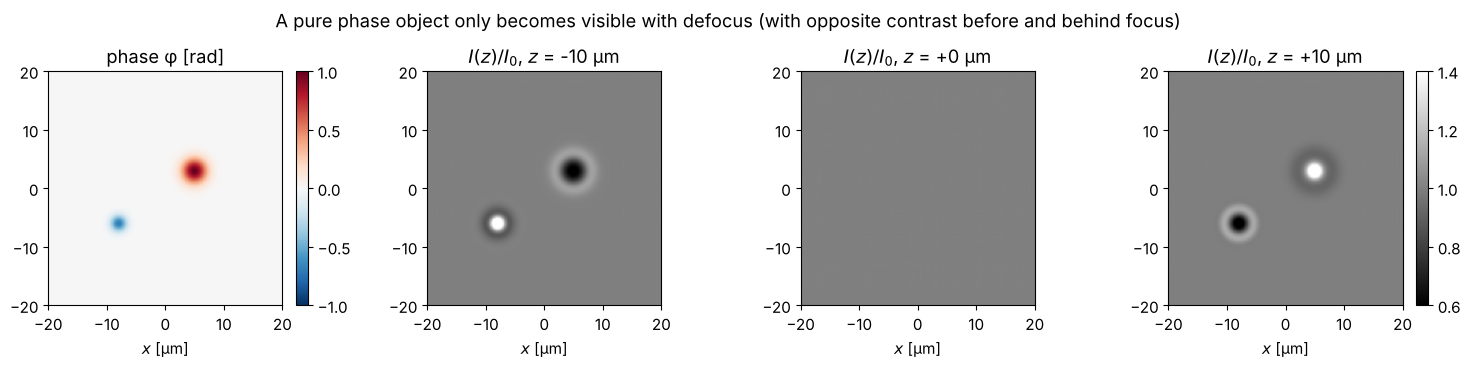

In [2]:
L, N = 60.0, 256
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
phase = 1.0*np.exp(-((X - 5)**2 + (Y - 3)**2)/(2*1.5**2)) - 0.7*np.exp(-((X + 8)**2 + (Y + 6)**2)/(2*1.0**2))
I0 = np.exp(-(X**2 + Y**2)/(2*20**2))
U0 = np.sqrt(I0)*np.exp(1j*phase)

def intensity_at(z):
    """Intensity after propagation by z. For z < 0 via time reversal (see notebook 05),
    so that rounding errors in evanescent frequencies do not blow up."""
    if z >= 0:
        return np.abs(rayleigh_sommerfeld_I_TF(U0, x, y, z, wl)[0])**2
    return np.abs(rayleigh_sommerfeld_I_TF(np.conj(U0), x, y, -z, wl)[0])**2

ext = (x[0], x[-1], y[0], y[-1])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
im = axes[0].imshow(phase, extent=ext, cmap="RdBu_r", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0], fraction=0.046); axes[0].set_title("phase φ [rad]")
for ax, z in zip(axes[1:], (-10, 0, 10)):
    I = intensity_at(z)
    im = ax.imshow(I/I0, extent=ext, cmap="gray", vmin=0.6, vmax=1.4)
    ax.set_title(f"$I(z)/I_0$, $z$ = {z:+d} µm")
fig.colorbar(im, ax=axes[3], fraction=0.046)
for ax in axes:
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20); ax.set_xlabel("$x$ [µm]")
fig.suptitle("A pure phase object only becomes visible with defocus (with opposite contrast before and behind focus)")
fig.tight_layout()

The positive phase bump acts like a converging lens (bright for $z > 0$), the
negative one like a diverging lens (dark). Before the focus it is the other way
round.

## 2. Forward direction: does the TIE hold?

`TIE.tie(phase, I, x, y, lam)` computes $\partial I/\partial z$ from the phase. For
comparison, the central difference quotient from two propagated images.

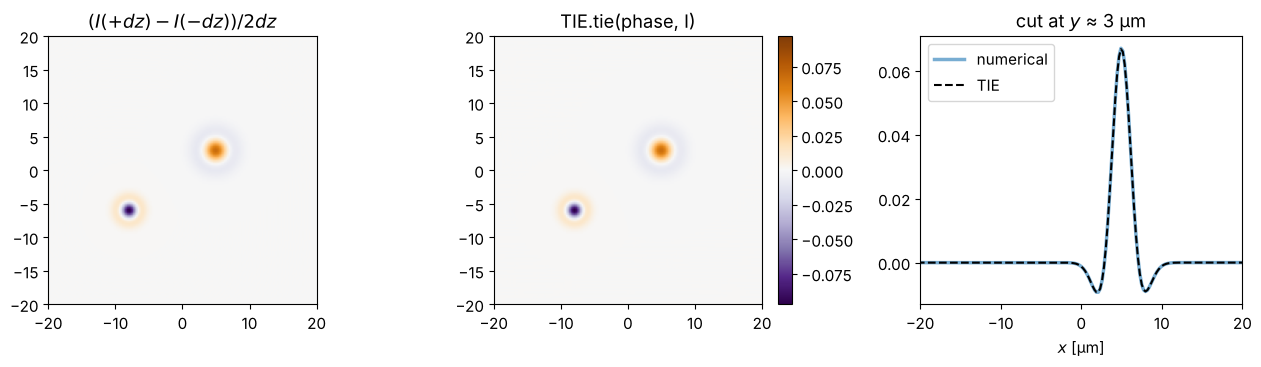

In [3]:
dz = 1.0
dIdz_num = (intensity_at(dz) - intensity_at(-dz))/(2*dz)
dIdz_tie = TIE.tie(phase, I0, x, y, wl)
vmax = np.abs(dIdz_tie).max()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, D, title in zip(axes[:2], (dIdz_num, dIdz_tie), ("$(I(+dz) - I(-dz))/2dz$", "TIE.tie(phase, I)")):
    im = ax.imshow(D, extent=ext, cmap="PuOr_r", vmin=-vmax, vmax=vmax)
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20); ax.set_title(title)
fig.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].plot(x, dIdz_num[N//2 + int(3/(x[1]-x[0]))], lw=2.5, alpha=0.6, label="numerical")
axes[2].plot(x, dIdz_tie[N//2 + int(3/(x[1]-x[0]))], "k--", label="TIE")
axes[2].set_xlim(-20, 20); axes[2].set_xlabel("$x$ [µm]"); axes[2].legend(); axes[2].set_title("cut at $y$ ≈ 3 µm")
fig.tight_layout()

## 3. Backward direction: phase from two images

`solve_tie(I, dI_dz, x, y, lam, alpha)` solves the TIE with two inverse Laplace
operators in Fourier space. The phase is only determined up to a constant; for the
comparison we subtract the mean in the illuminated region.

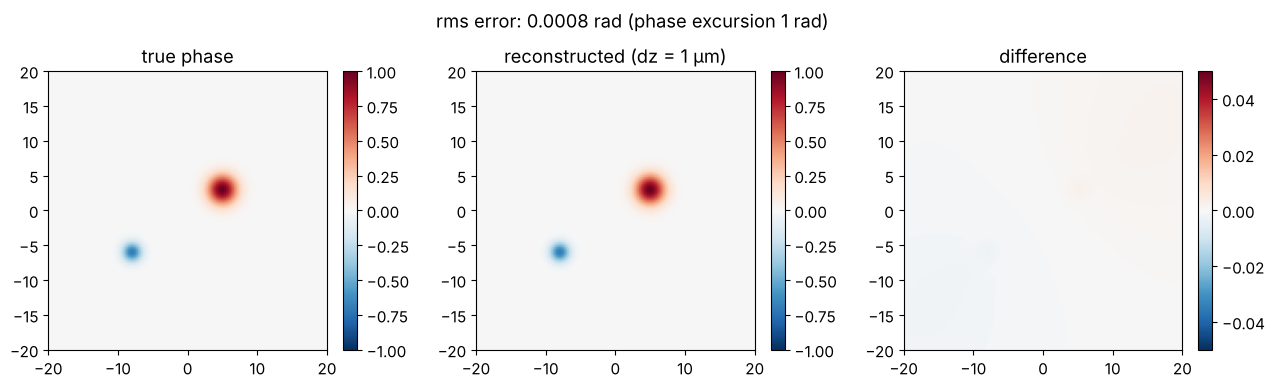

In [4]:
mask = I0 > 0.2
def rms_error(ph):
    e = (ph - phase)[mask]
    return np.sqrt(np.mean((e - e.mean())**2))

phase_rec = TIE.solve_tie(I0, dIdz_num, x, y, wl, 0.0)
offset = np.mean((phase_rec - phase)[mask])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, P, title in zip(axes, (phase, phase_rec - offset, phase_rec - offset - phase),
                        ("true phase", "reconstructed (dz = 1 µm)", "difference")):
    lim = 1 if title != "difference" else 0.05
    im = ax.imshow(np.where(mask, P, np.nan), extent=ext, cmap="RdBu_r", vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20); ax.set_title(title)
fig.suptitle(f"rms error: {rms_error(phase_rec):.4f} rad (phase excursion 1 rad)")
fig.tight_layout()

## 4. The trade-off in the defocus distance

In practice the images are noisy. The difference quotient $(I_+ - I_-)/2\Delta z$
amplifies the noise by $1/\Delta z$: small distances are sensitive to noise. Large
distances, on the other hand, violate the assumption that $I$ changes linearly with
$z$ (diffraction "smears out" the fine structures). In between lies an optimum that
depends on the noise level.

The second parameter is the **regularization** `alpha`: the inverse Laplace
operator $-1/(k_x^2 + k_y^2)$ amplifies low frequencies and thus low-frequency
noise. With `alpha > 0` it is damped to $-1/(k_x^2 + k_y^2 + \alpha)$.

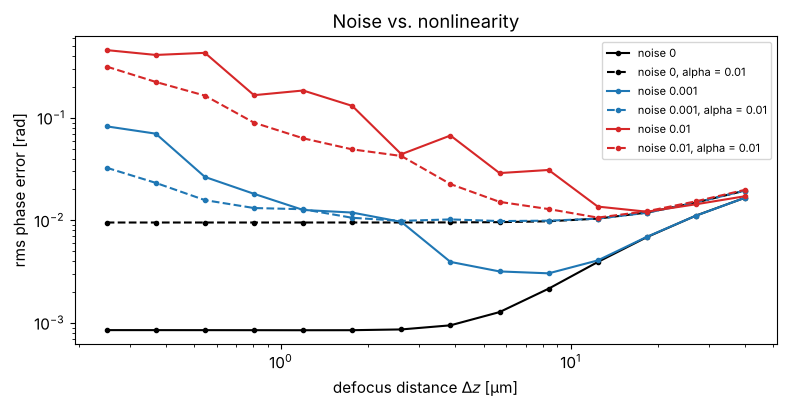

In [5]:
rng = np.random.default_rng(0)
dz_vals = np.logspace(np.log10(0.25), np.log10(40), 14)
noise_levels = (0.0, 1e-3, 1e-2)
fig, ax = plt.subplots(figsize=(8, 4.2))
for noise, c in zip(noise_levels, ("k", "C0", "C3")):
    for alpha, ls in ((0.0, "-"), (1e-2, "--")):
        errs = []
        for dz in dz_vals:
            Ip = intensity_at(dz) + noise*rng.standard_normal(X.shape)
            Im = intensity_at(-dz) + noise*rng.standard_normal(X.shape)
            errs.append(rms_error(TIE.solve_tie(I0, (Ip - Im)/(2*dz), x, y, wl, alpha)))
        label = f"noise {noise:g}" + (f", alpha = {alpha:g}" if alpha else "")
        ax.loglog(dz_vals, errs, ls, color=c, marker="o", ms=3, label=label)
ax.set_xlabel("defocus distance $\\Delta z$ [µm]"); ax.set_ylabel("rms phase error [rad]")
ax.set_title("Noise vs. nonlinearity"); ax.legend(fontsize=8)
fig.tight_layout()

## 5. More planes: Savitzky-Golay derivative

With more than two images, the derivative can be estimated more robustly.
`utils.get_z_derivative(stack, dz, order)` fits a polynomial to the intensity along
$z$ in every pixel (Savitzky-Golay) and evaluates its derivative in the central
plane. More planes in the same $z$ range average out the noise. A higher
polynomial degree would reduce the systematic error due to the nonlinearity, but
amplifies the noise again; in this noise-dominated case, the straight line
(degree 1) is best.

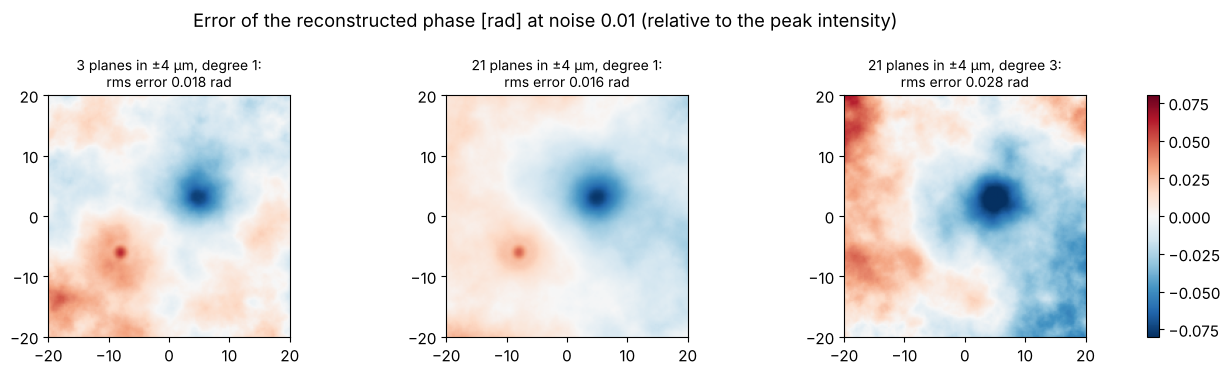

In [6]:
noise = 1e-2
z_max = 4.0
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
results = {}
for n_planes, order in ((3, 1), (21, 1), (21, 3)):
    z_planes = np.linspace(-z_max, z_max, n_planes)
    stack = np.dstack([intensity_at(z) + noise*rng.standard_normal(X.shape) for z in z_planes])
    dIdz = get_z_derivative(stack, z_planes[1] - z_planes[0], order)
    results[(n_planes, order)] = TIE.solve_tie(I0, dIdz, x, y, wl, 1e-2)
for ax, ((n_planes, order), ph) in zip(axes, results.items()):
    err = ph - phase - np.mean((ph - phase)[mask])
    im = ax.imshow(np.where(mask, err, np.nan), extent=ext, cmap="RdBu_r", vmin=-0.08, vmax=0.08)
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20)
    ax.set_title(f"{n_planes} planes in ±{z_max:.0f} µm, degree {order}:\nrms error {rms_error(ph):.3f} rad", fontsize=10)
fig.suptitle(f"Error of the reconstructed phase [rad] at noise {noise} (relative to the peak intensity)")
fig.tight_layout()
fig.colorbar(im, ax=axes, fraction=0.02)

## 6. Iterative refinement

After the first solution, `enhanced_tie_solve()` computes the residual
$\partial_z I - \mathrm{TIE}(\varphi)$, solves the TIE for it again and adds the
correction. This helps when the intensity is strongly non-uniform, because
`solve_tie()` uses an approximation for the term with $1/I$. We test this with a
strongly structured illumination.

Enanced TIE iteration 1
Enanced TIE iteration 2
Enanced TIE iteration 3
Enanced TIE iteration 4
Enanced TIE iteration 5


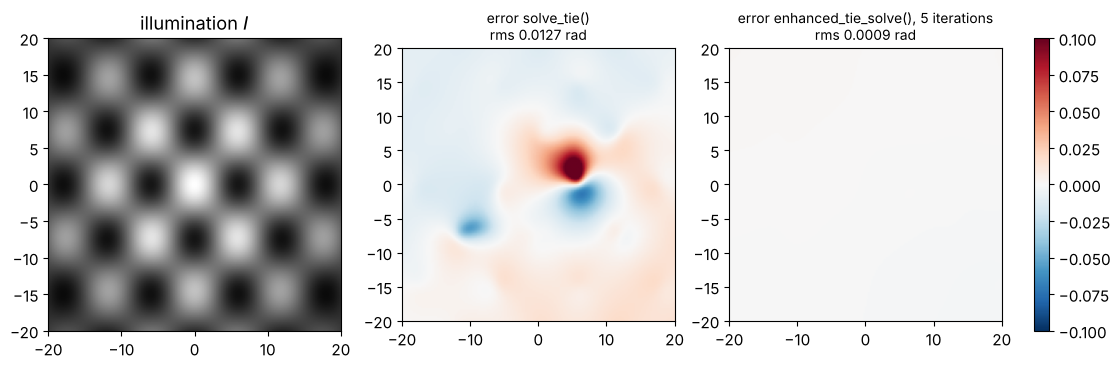

In [7]:
I_struct = I0*(0.55 + 0.45*np.cos(2*np.pi*X/12)*np.cos(2*np.pi*Y/15))
dIdz_struct = TIE.tie(phase, I_struct, x, y, wl)
ph0 = TIE.solve_tie(I_struct, dIdz_struct, x, y, wl, 0.0)
ph_enh = TIE.enhanced_tie_solve(5, I_struct, dIdz_struct, x, y, wl, 0.0, true_phase=None)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].imshow(I_struct, extent=ext, cmap="gray"); axes[0].set_title("illumination $I$")
for ax, ph, title in zip(axes[1:], (ph0, ph_enh), ("solve_tie()", "enhanced_tie_solve(), 5 iterations")):
    err = np.where(mask, ph - phase - np.mean((ph - phase)[mask]), np.nan)
    im = ax.imshow(err, extent=ext, cmap="RdBu_r", vmin=-0.1, vmax=0.1)
    ax.set_title(f"error {title}\nrms {rms_error(ph):.4f} rad", fontsize=10)
fig.colorbar(im, ax=axes[1:], fraction=0.03)
for ax in axes:
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20)